# Fragmentation Explainability Analysis

explainability of fragmentation DAGs by chemical class.


In [127]:
import gc
import pickle
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

DATA_ROOT = Path("../data")

## 1. Explainable Masses by Chemical Class (Fragmentation DAG Coverage)

Uses `mol_stats_df` from `data/frag/nps_nist23_d3/`, which records per-molecule fragmentation DAG statistics.

**Key metric – weighted recall (`wrecall_10ppm_h4`)**: fraction of total spectral peak intensity whose *m/z* is within 10 ppm of at least one formula mass in the fragmentation DAG (allowing up to 4 H-shifts).  A low value means the DAG is missing fragments needed to explain the observed spectrum — i.e. "low explainability".

In [128]:
# Load frag DAG stats and join with ClassyFire taxonomy
mol_stats_df = pd.read_pickle(DATA_ROOT / "frag/nps_nist23_d3/mol_stats_df.pkl")

cf_df = pd.read_pickle(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl")
cf_cols = ["mol_id", "kingdom", "superklass", "klass", "subklass"]

frag_cf = mol_stats_df.merge(cf_df[cf_cols], on="mol_id", how="left")
print(f"mol_stats_df rows: {len(mol_stats_df):,}  |  after CF join: {len(frag_cf):,}")
print(f"CF annotation coverage: {frag_cf['superklass'].notna().mean():.1%}")

WRECALL_COL = "wrecall_10ppm_h4"  # primary explainability metric
print(f"\nOverall {WRECALL_COL} stats:")
print(frag_cf[WRECALL_COL].describe().round(3))

del mol_stats_df
gc.collect()

mol_stats_df rows: 1,486  |  after CF join: 1,486
CF annotation coverage: 100.0%

Overall wrecall_10ppm_h4 stats:
count    1486.000
mean        0.894
std         0.109
min         0.105
25%         0.849
50%         0.932
75%         0.970
max         1.000
Name: wrecall_10ppm_h4, dtype: float64


0

Weighted recall by superclass:
                                         median_wrecall  mean_wrecall  n_mols
superklass                                                                   
alkaloids and derivatives                         0.974         0.934      16
organometallic compounds                          0.960         0.960       1
organohalogen compounds                           0.952         0.947      10
nucleosides, nucleotides, and analogues           0.948         0.960       3
organic nitrogen compounds                        0.946         0.920      33
hydrocarbons                                      0.945         0.887       4
phenylpropanoids and polyketides                  0.942         0.869      43
organic acids and derivatives                     0.940         0.902      98
organic oxygen compounds                          0.939         0.892      43
benzenoids                                        0.939         0.896     121
acetylides                       

/tmp/ipykernel_1289096/1367276464.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(groups_super, labels=labels_super, patch_artist=True, medianprops=dict(color="black", linewidth=2))


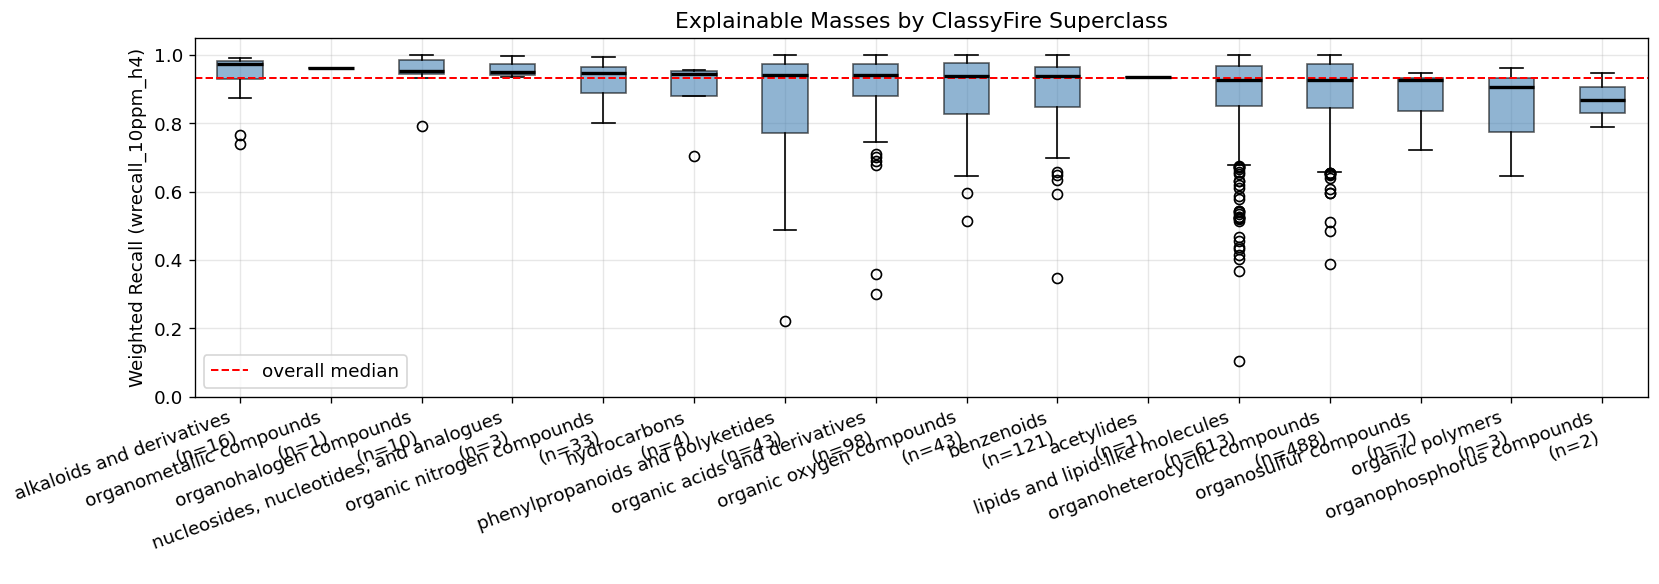

In [129]:
# --- Weighted recall by ClassyFire Superclass ---
df_super = frag_cf.dropna(subset=["superklass"])
super_order = (
    df_super.groupby("superklass")[WRECALL_COL]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

super_stats = (
    df_super.groupby("superklass")[WRECALL_COL]
    .agg(["median", "mean", "count"])
    .reindex(super_order)
    .round(3)
)
super_stats.columns = ["median_wrecall", "mean_wrecall", "n_mols"]
print("Weighted recall by superclass:")
print(super_stats.to_string())

groups_super = [df_super[df_super["superklass"] == s][WRECALL_COL].dropna().values for s in super_order]
labels_super = [f"{s}\n(n={len(g)})" for s, g in zip(super_order, groups_super)]

fig, ax = plt.subplots(figsize=(14, 5))
bp = ax.boxplot(groups_super, labels=labels_super, patch_artist=True, medianprops=dict(color="black", linewidth=2))
for patch in bp["boxes"]:
    patch.set_facecolor("steelblue")
    patch.set_alpha(0.6)
ax.axhline(frag_cf[WRECALL_COL].median(), color="red", linestyle="--", linewidth=1.2, label="overall median")
ax.set_ylabel(f"Weighted Recall ({WRECALL_COL})")
ax.set_title("Explainable Masses by ClassyFire Superclass")
ax.set_ylim(0, 1.05)
ax.legend()
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Weighted recall by class (top 20):
                                     median_wrecall  mean_wrecall  n_mols
klass                                                                    
quinolines and derivatives                    0.956         0.913      27
organonitrogen compounds                      0.946         0.920      33
azoles                                        0.943         0.924      30
coumarins and derivatives                     0.942         0.895      14
fatty acyls                                   0.942         0.911      36
carboxylic acids and derivatives              0.940         0.902      72
organooxygen compounds                        0.939         0.892      43
piperidines                                   0.937         0.910      37
diazanaphthalenes                             0.936         0.903      14
benzene and substituted derivatives           0.934         0.893      98
indoles and derivatives                       0.929         0.886      31
pre

/tmp/ipykernel_1289096/597773893.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(groups_klass, labels=labels_klass, patch_artist=True, medianprops=dict(color="black", linewidth=2))


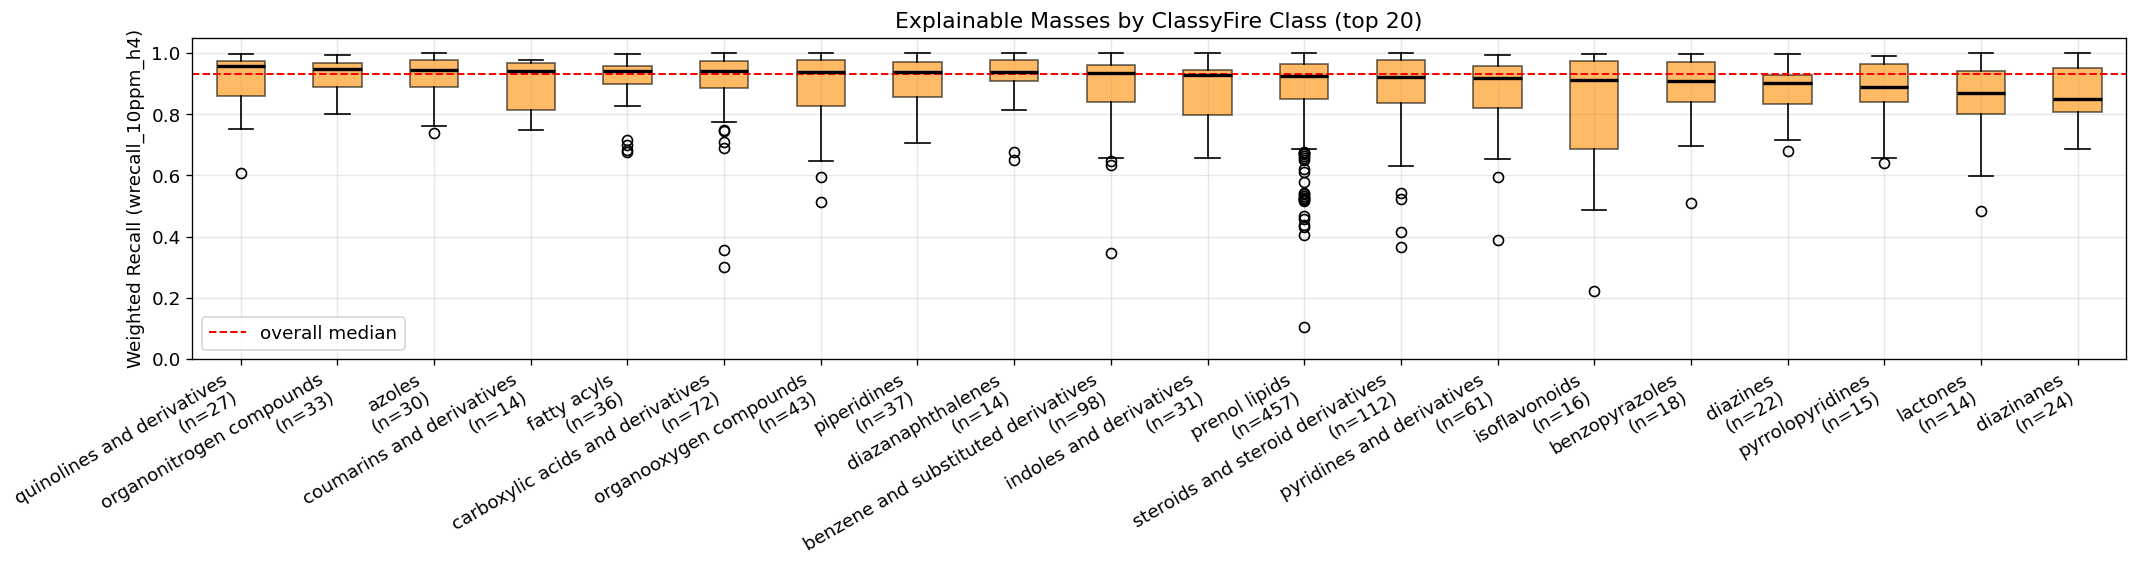

In [130]:
# --- Weighted recall by ClassyFire Class (top 20 by count) ---
top20_klass = frag_cf["klass"].value_counts().head(20).index.tolist()
df_klass_fr = frag_cf[frag_cf["klass"].isin(top20_klass)].dropna(subset=["klass"])

klass_order = (
    df_klass_fr.groupby("klass")[WRECALL_COL]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

klass_stats = (
    df_klass_fr.groupby("klass")[WRECALL_COL]
    .agg(["median", "mean", "count"])
    .reindex(klass_order)
    .round(3)
)
klass_stats.columns = ["median_wrecall", "mean_wrecall", "n_mols"]
print("Weighted recall by class (top 20):")
print(klass_stats.to_string())

groups_klass = [df_klass_fr[df_klass_fr["klass"] == k][WRECALL_COL].dropna().values for k in klass_order]
labels_klass = [f"{k}\n(n={len(g)})" for k, g in zip(klass_order, groups_klass)]

fig, ax = plt.subplots(figsize=(18, 5))
bp = ax.boxplot(groups_klass, labels=labels_klass, patch_artist=True, medianprops=dict(color="black", linewidth=2))
for patch in bp["boxes"]:
    patch.set_facecolor("darkorange")
    patch.set_alpha(0.6)
ax.axhline(frag_cf[WRECALL_COL].median(), color="red", linestyle="--", linewidth=1.2, label="overall median")
ax.set_ylabel(f"Weighted Recall ({WRECALL_COL})")
ax.set_title("Explainable Masses by ClassyFire Class (top 20)")
ax.set_ylim(0, 1.05)
ax.legend()
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

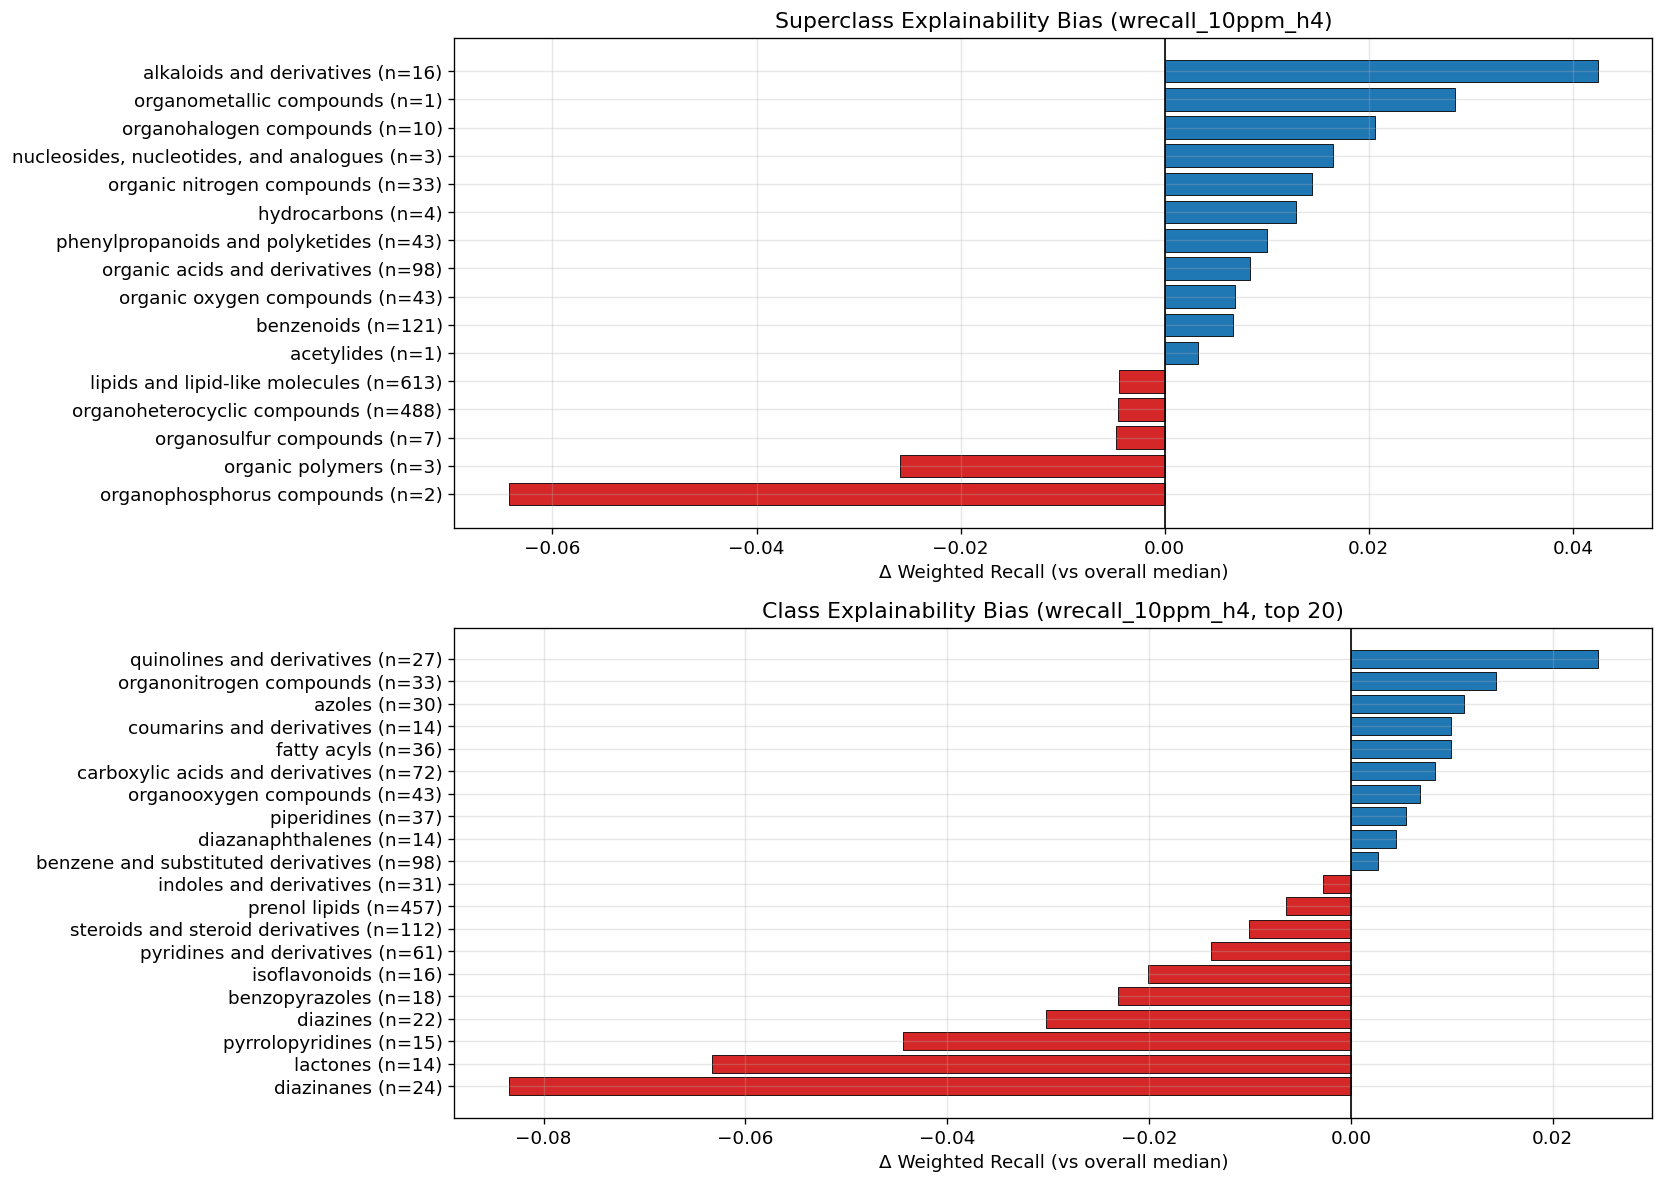


Overall median wrecall_10ppm_h4 = 0.932

Lowest-explainability superclasses:
                                 med_wrecall   bias  count
superklass                                                
organophosphorus compounds             0.868 -0.064      2
organic polymers                       0.906 -0.026      3
organosulfur compounds                 0.927 -0.005      7
organoheterocyclic compounds           0.927 -0.005    488
lipids and lipid-like molecules        0.927 -0.004    613

Lowest-explainability classes (top-20 by count):
                                  med_wrecall   bias  count
klass                                                      
diazinanes                              0.848 -0.083     24
lactones                                0.868 -0.063     14
pyrrolopyridines                        0.887 -0.044     15
diazines                                0.902 -0.030     22
benzopyrazoles                          0.909 -0.023     18
isoflavonoids                          

In [131]:
# --- Bias plot: deviation from overall median, by superclass and class ---
overall_median = frag_cf[WRECALL_COL].median()

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Superclass bias
bias_super = (
    df_super.groupby("superklass")[WRECALL_COL]
    .agg(["median", "count"])
    .rename(columns={"median": "med_wrecall"})
)
bias_super["bias"] = bias_super["med_wrecall"] - overall_median
bias_super = bias_super.sort_values("bias", ascending=True)
colors_super = ["#d62728" if b < 0 else "#1f77b4" for b in bias_super["bias"]]
axes[0].barh(
    [f"{s} (n={n})" for s, n in zip(bias_super.index, bias_super["count"])],
    bias_super["bias"],
    color=colors_super,
    edgecolor="black",
    linewidth=0.5,
)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlabel("Δ Weighted Recall (vs overall median)")
axes[0].set_title(f"Superclass Explainability Bias ({WRECALL_COL})")

# Class bias (top 20)
bias_klass = (
    df_klass_fr.groupby("klass")[WRECALL_COL]
    .agg(["median", "count"])
    .rename(columns={"median": "med_wrecall"})
)
bias_klass["bias"] = bias_klass["med_wrecall"] - overall_median
bias_klass = bias_klass.sort_values("bias", ascending=True)
colors_klass = ["#d62728" if b < 0 else "#1f77b4" for b in bias_klass["bias"]]
axes[1].barh(
    [f"{k} (n={n})" for k, n in zip(bias_klass.index, bias_klass["count"])],
    bias_klass["bias"],
    color=colors_klass,
    edgecolor="black",
    linewidth=0.5,
)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlabel("Δ Weighted Recall (vs overall median)")
axes[1].set_title(f"Class Explainability Bias ({WRECALL_COL}, top 20)")

plt.tight_layout()
plt.show()

print(f"\nOverall median {WRECALL_COL} = {overall_median:.3f}")
print("\nLowest-explainability superclasses:")
print(bias_super.head(5)[["med_wrecall", "bias", "count"]].round(3).to_string())
print("\nLowest-explainability classes (top-20 by count):")
print(bias_klass.head(8)[["med_wrecall", "bias", "count"]].round(3).to_string())

In [132]:
del frag_cf, cf_df
gc.collect()


31275

## 2. Explainable Masses by Chemical Class (CE-Controlled)

Uses `spec_stats_df` from `data/frag/nps_nist23_d3/` (per-spectrum fragmentation DAG stats) joined
with `spec_df` for instrument/CE info and ClassyFire taxonomy.

**Metric – weighted recall (`wrecall_10ppm_h4`)**: fraction of total spectral peak intensity
whose *m/z* is ≤ 10 ppm from a formula mass in the fragmentation DAG (≤4 H-shifts allowed).

**CE control**: higher collision energies produce more/different fragment ions that the DAG
may not cover, inflating 'unexplained' intensity. To avoid confounding class effects with CE
effects, we compute **CE-adjusted wrecall** = residual after subtracting the per-instrument
CE-bin median. We also show raw wrecall stratified by low/mid/high CE tertile.

In [133]:
# ── Load data ────────────────────────────────────────────────────────────────
spec_stats_df = pd.read_pickle(DATA_ROOT / "frag/nps_nist23_d3/spec_stats_df.pkl")

cf_df = pd.read_pickle(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl")

spec_meta = pd.read_pickle(DATA_ROOT / "proc/nist23/spec_df.pkl")[
    ["spec_id", "inst_type", "nce", "ace"]
]

WRECALL_COL = "wrecall_10ppm_h4"  # primary explainability metric

# Merge spec-level wrecall ← spec metadata ← ClassyFire
frag_spec = (
    spec_stats_df[["spec_id", "mol_id", WRECALL_COL]]
    .merge(spec_meta, on="spec_id", how="inner")
    .merge(cf_df[["mol_id", "superklass", "klass", "subklass"]], on="mol_id", how="left")
)

# ── Native CE per instrument (FT → NCE %, QTOF/IT → ACE eV) ─────────────────
_CE_COL = {"FT": "nce", "QTOF": "ace", "IT": "nce"}
frag_spec["native_ce"] = np.nan
for _inst, _col in _CE_COL.items():
    _m = frag_spec["inst_type"] == _inst
    frag_spec.loc[_m, "native_ce"] = frag_spec.loc[_m, _col]

# ── CE tertile bins per instrument ───────────────────────────────────────────
frag_spec["ce_bin"] = frag_spec.groupby("inst_type", observed=True)["native_ce"].transform(
    lambda x: pd.qcut(x.rank(method="first"), q=3, labels=["low", "mid", "high"])
)

# ── CE-adjusted wrecall (residual) ───────────────────────────────────────────
# Subtract per-(inst_type, ce_bin) median to isolate molecular-class effect
bin_medians = frag_spec.groupby(["inst_type", "ce_bin"], observed=True)[WRECALL_COL].transform("median")
frag_spec["wrecall_adj"] = frag_spec[WRECALL_COL] - bin_medians

print(f"Spectra: {len(frag_spec):,}  |  CF coverage: {frag_spec['superklass'].notna().mean():.1%}")
print(f"Overall median wrecall: {frag_spec[WRECALL_COL].median():.3f}")
print("\nCE bins (FT = NCE%, QTOF = ACE eV):")
print(
    frag_spec.groupby(["inst_type", "ce_bin"], observed=True)["native_ce"]
    .agg(["min", "max", "count"])
    .to_string()
)

del spec_stats_df
gc.collect()

Spectra: 27,831  |  CF coverage: 100.0%
Overall median wrecall: 0.987

CE bins (FT = NCE%, QTOF = ACE eV):
                   min    max  count
inst_type ce_bin                    
FT        low      2.0   35.0   8731
          mid     35.0   65.0   8730
          high    65.0  195.0   8731
QTOF      low      2.0   15.0    546
          mid     15.0   27.0    546
          high    27.0   45.0    547


0

In [134]:
# ── CE-adjusted wrecall by Superclass ────────────────────────────────────────
df_s = frag_spec.dropna(subset=["superklass"])

super_adj = (
    df_s.groupby("superklass")[[WRECALL_COL, "wrecall_adj"]]
    .agg("median")
    .rename(columns={WRECALL_COL: "med_raw", "wrecall_adj": "med_adj"})
    .join(df_s.groupby("superklass")[WRECALL_COL].count().rename("n_specs"))
    .sort_values("med_adj")
    .round(3)
)
print(f"Superclass — raw vs CE-adjusted median wrecall (sorted by adj, low=harder):")
print(super_adj.to_string())

Superclass — raw vs CE-adjusted median wrecall (sorted by adj, low=harder):
                                         med_raw  med_adj  n_specs
superklass                                                        
organic polymers                           0.949   -0.036       56
organosulfur compounds                     0.954   -0.034      103
acetylides                                 0.966   -0.020       16
organophosphorus compounds                 0.966   -0.018       43
hydrocarbons                               0.975   -0.013       74
organometallic compounds                   0.982   -0.005       14
organic oxygen compounds                   0.985   -0.002      796
lipids and lipid-like molecules            0.986   -0.001    11895
organoheterocyclic compounds               0.988    0.000     9115
phenylpropanoids and polyketides           0.988    0.001      883
benzenoids                                 0.989    0.001     2032
alkaloids and derivatives                  0.997    0

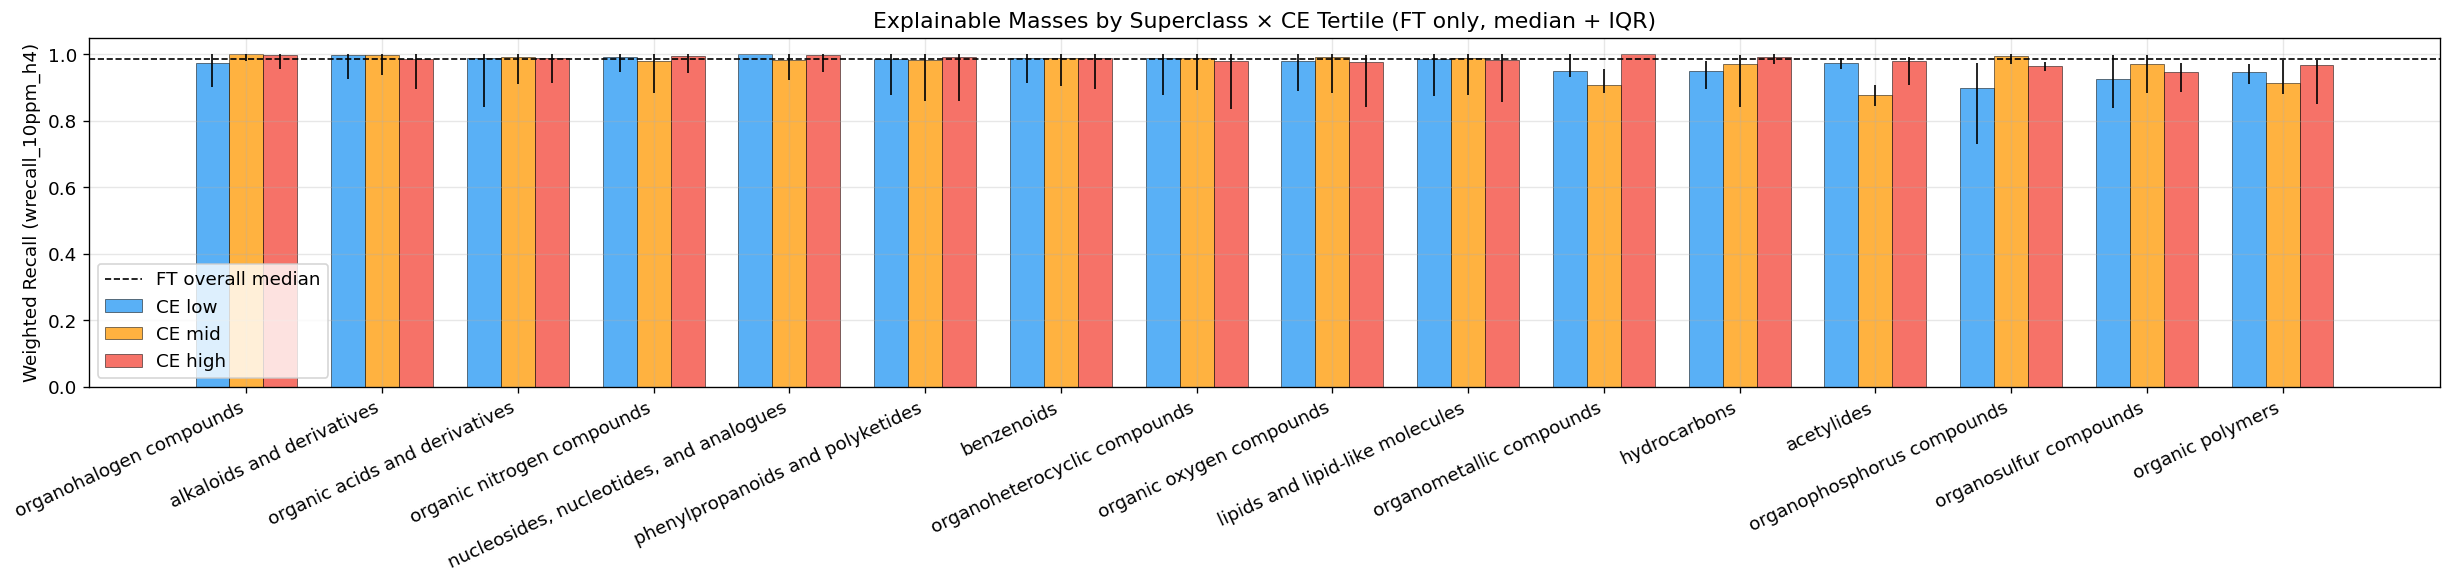

In [135]:
# ── Bar chart: raw wrecall by Superclass × CE tertile (FT only) ─────────────
df_ft = frag_spec[(frag_spec["inst_type"] == "FT") & frag_spec["superklass"].notna()].copy()

CE_COLORS = {"low": "#2196F3", "mid": "#FF9800", "high": "#F44336"}
super_order_ft = (
    df_ft.groupby("superklass")[WRECALL_COL].median().sort_values(ascending=False).index.tolist()
)

fig, ax = plt.subplots(figsize=(max(14, len(super_order_ft) * 1.3), 5))
width = 0.25
x = np.arange(len(super_order_ft))

for i, ce_lbl in enumerate(["low", "mid", "high"]):
    medians, q1s, q3s = [], [], []
    for s in super_order_ft:
        vals = df_ft[(df_ft["superklass"] == s) & (df_ft["ce_bin"] == ce_lbl)][WRECALL_COL].dropna()
        medians.append(vals.median() if len(vals) else np.nan)
        q1s.append(vals.quantile(0.25) if len(vals) else np.nan)
        q3s.append(vals.quantile(0.75) if len(vals) else np.nan)
    medians, q1s, q3s = np.array(medians), np.array(q1s), np.array(q3s)
    ax.bar(x + i * width, medians, width=width, label=f"CE {ce_lbl}",
           color=CE_COLORS[ce_lbl], alpha=0.75, edgecolor="black", linewidth=0.4)
    ax.vlines(x + i * width, q1s, q3s, color="black", linewidth=1.0)

ax.axhline(df_ft[WRECALL_COL].median(), color="black", linestyle="--", linewidth=1, label="FT overall median")
ax.set_xticks(x + width)
ax.set_xticklabels(super_order_ft, rotation=25, ha="right")
ax.set_ylabel(f"Weighted Recall ({WRECALL_COL})")
ax.set_title(f"Explainable Masses by Superclass × CE Tertile (FT only, median + IQR)")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

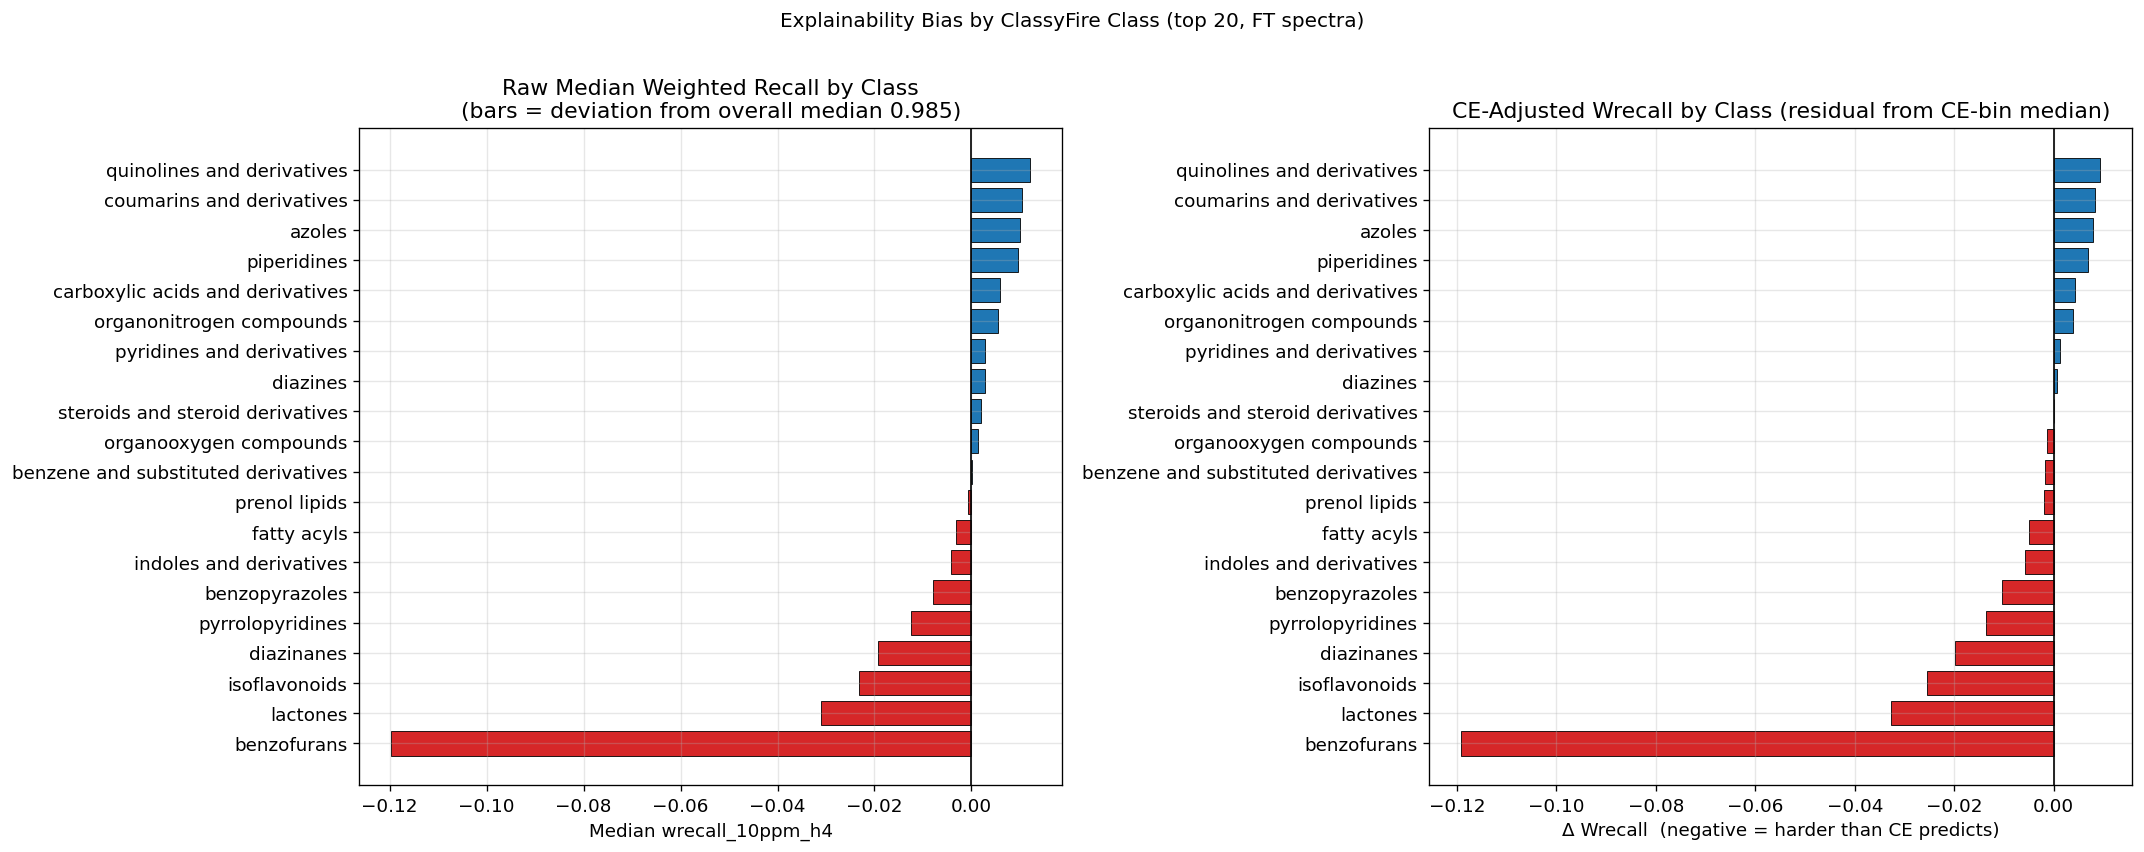

Class explainability (FT, CE-adjusted, sorted by adj):
                                     med_raw  med_adj  n_specs
klass                                                         
benzofurans                            0.865   -0.119      309
lactones                               0.954   -0.033      270
isoflavonoids                          0.962   -0.025      279
diazinanes                             0.965   -0.020      394
pyrrolopyridines                       0.972   -0.014      264
benzopyrazoles                         0.977   -0.010      272
indoles and derivatives                0.981   -0.006      515
fatty acyls                            0.982   -0.005      551
prenol lipids                          0.984   -0.002     8453
benzene and substituted derivatives    0.985   -0.002     1557
organooxygen compounds                 0.986   -0.001      732
steroids and steroid derivatives       0.987    0.000     2136
diazines                               0.987    0.001      337


In [136]:
# ── CE-adjusted bias by Class (top 20) ──────────────────────────────────────
top20_klass = frag_spec["klass"].value_counts().head(20).index.tolist()
df_ft_klass = frag_spec[
    (frag_spec["inst_type"] == "FT") & frag_spec["klass"].isin(top20_klass)
].dropna(subset=["klass"])

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (col, title, xlabel) in zip(axes, [
    (WRECALL_COL,
     "Raw Median Weighted Recall by Class",
     f"Median {WRECALL_COL}"),
    ("wrecall_adj",
     "CE-Adjusted Wrecall by Class (residual from CE-bin median)",
     "Δ Wrecall  (negative = harder than CE predicts)"),
]):
    vals = df_ft_klass.groupby("klass")[col].median().sort_values(ascending=True)
    ref = df_ft_klass[WRECALL_COL].median() if col == WRECALL_COL else 0.0
    colors = ["#d62728" if v < ref else "#1f77b4" for v in vals]
    bar_vals = vals.values - ref if col == WRECALL_COL else vals.values
    ax.barh(vals.index, bar_vals, color=colors, edgecolor="black", linewidth=0.5)
    ax.axvline(0, color="black", linewidth=1)
    if col == WRECALL_COL:
        ax.set_title(f"{title}\n(bars = deviation from overall median {ref:.3f})")
    else:
        ax.set_title(title)
    ax.set_xlabel(xlabel)

plt.suptitle("Explainability Bias by ClassyFire Class (top 20, FT spectra)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

# Print summary table
klass_summary = (
    df_ft_klass.groupby("klass")[[WRECALL_COL, "wrecall_adj"]]
    .agg("median")
    .rename(columns={WRECALL_COL: "med_raw", "wrecall_adj": "med_adj"})
    .join(df_ft_klass.groupby("klass")[WRECALL_COL].count().rename("n_specs"))
    .sort_values("med_adj")
    .round(3)
)
print("Class explainability (FT, CE-adjusted, sorted by adj):")
print(klass_summary.to_string())

In [137]:
del frag_spec
gc.collect()


17484

## 3. H-Shift Sensitivity: Comparing wrecall_10ppm_h1 → h4

How much does relaxing the H-shift tolerance (h1 → h4) improve DAG coverage?
Each step allows one additional H-shift when matching formula masses to observed peaks.

- **h1**: ≤1 H-shift allowed
- **h2**: ≤2 H-shifts allowed
- **h3**: ≤3 H-shifts allowed
- **h4**: ≤4 H-shifts allowed

Overall mol-level wrecall_10ppm stats:
       wrecall_10ppm_h1  wrecall_10ppm_h2  wrecall_10ppm_h3  wrecall_10ppm_h4
count          1486.000          1486.000          1486.000          1486.000
mean              0.369             0.804             0.874             0.894
std               0.173             0.158             0.114             0.109
min               0.000             0.096             0.098             0.105
25%               0.245             0.732             0.821             0.849
50%               0.320             0.849             0.903             0.932
75%               0.483             0.919             0.958             0.970
max               0.989             1.000             1.000             1.000


/tmp/ipykernel_1289096/3221454190.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


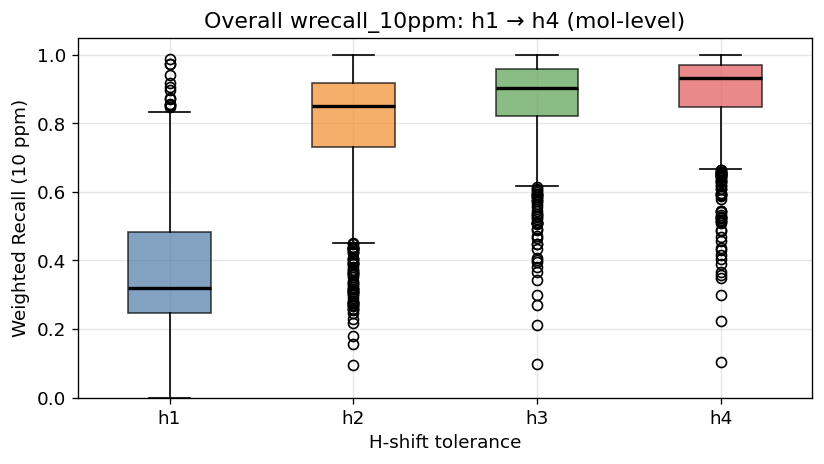


Median wrecall and incremental gain per H-shift step:
          metric   median  gain_vs_prev
wrecall_10ppm_h1 0.319507           NaN
wrecall_10ppm_h2 0.849413        0.5299
wrecall_10ppm_h3 0.902698        0.0533
wrecall_10ppm_h4 0.931790        0.0291


In [138]:
# ── Load mol-level stats for all four h-shift variants ───────────────────────
H_COLS = ["wrecall_10ppm_h1", "wrecall_10ppm_h2", "wrecall_10ppm_h3", "wrecall_10ppm_h4"]
H_LABELS = ["h1", "h2", "h3", "h4"]
H_COLORS = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759"]

mol_stats_df = pd.read_pickle(DATA_ROOT / "frag/nps_nist23_d3/mol_stats_df.pkl")
cf_df = pd.read_pickle(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl")
cf_cols = ["mol_id", "kingdom", "superklass", "klass", "subklass"]

hcf = mol_stats_df.merge(cf_df[cf_cols], on="mol_id", how="left")
del mol_stats_df
gc.collect()

# ── Overall distribution (box plots) ─────────────────────────────────────────
print("Overall mol-level wrecall_10ppm stats:")
print(hcf[H_COLS].describe().round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
bp = ax.boxplot(
    [hcf[c].dropna().values for c in H_COLS],
    labels=H_LABELS,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
)
for patch, color in zip(bp["boxes"], H_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xlabel("H-shift tolerance")
ax.set_ylabel("Weighted Recall (10 ppm)")
ax.set_title("Overall wrecall_10ppm: h1 → h4 (mol-level)")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

# ── Incremental gain table ────────────────────────────────────────────────────
gain = pd.DataFrame({"metric": H_COLS, "median": [hcf[c].median() for c in H_COLS]})
gain["gain_vs_prev"] = gain["median"].diff().round(4)
print("\nMedian wrecall and incremental gain per H-shift step:")
print(gain.to_string(index=False))

Spec-level (FT) wrecall_10ppm stats:
       wrecall_10ppm_h1  wrecall_10ppm_h2  wrecall_10ppm_h3  wrecall_10ppm_h4
count         26192.000         26192.000         26192.000         26192.000
mean              0.376             0.787             0.856             0.876
std               0.336             0.283             0.242             0.228
min               0.000             0.000             0.000             0.000
25%               0.076             0.661             0.830             0.876
50%               0.263             0.934             0.978             0.986
75%               0.678             0.993             0.999             1.000
max               1.000             1.000             1.000             1.000


/tmp/ipykernel_1289096/4020653491.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


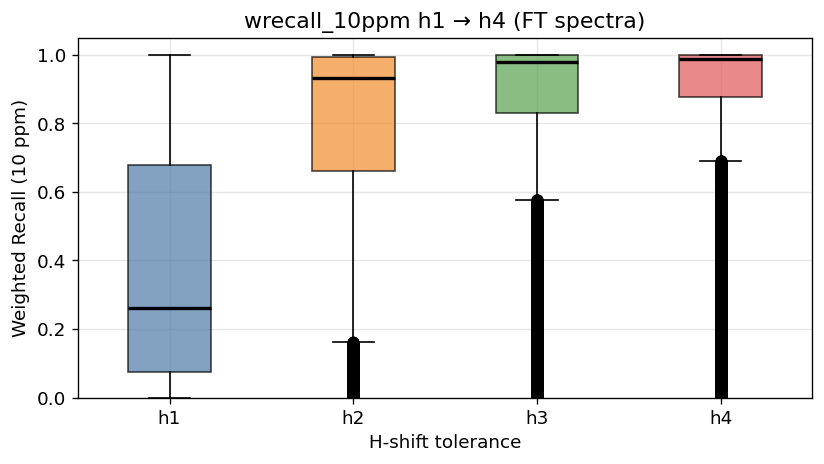

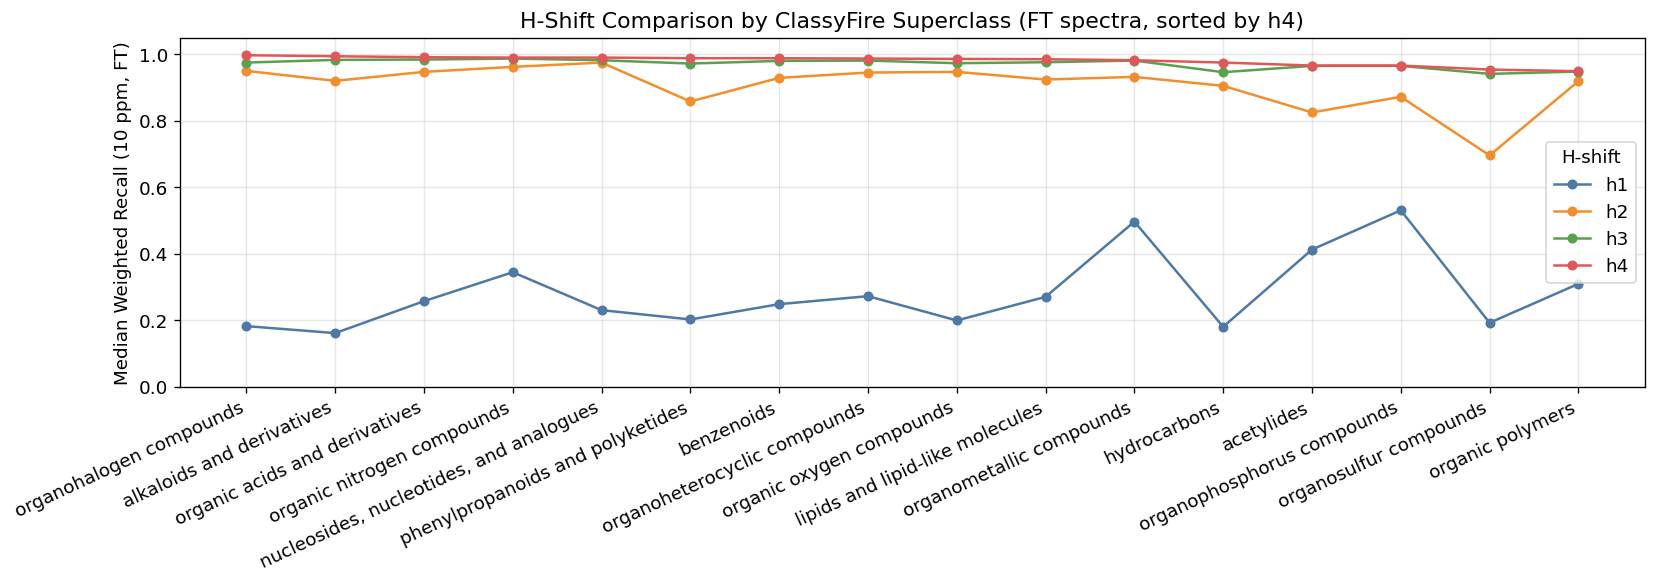

4261

In [139]:
# ── Spec-level h-shift comparison (FT, overall distribution) ─────────────────
spec_stats_df = pd.read_pickle(DATA_ROOT / "frag/nps_nist23_d3/spec_stats_df.pkl")
cf_df2 = pd.read_pickle(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl")
spec_meta = pd.read_pickle(DATA_ROOT / "proc/nist23/spec_df.pkl")[
    ["spec_id", "inst_type", "nce", "ace"]
]

hspec = (
    spec_stats_df[["spec_id", "mol_id"] + H_COLS]
    .merge(spec_meta, on="spec_id", how="inner")
    .merge(cf_df2[["mol_id", "superklass"]], on="mol_id", how="left")
)
del spec_stats_df, cf_df2
gc.collect()

hspec_ft = hspec[hspec["inst_type"] == "FT"]

print("Spec-level (FT) wrecall_10ppm stats:")
print(hspec_ft[H_COLS].describe().round(3).to_string())

# ── Box plots: spec-level FT ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
bp = ax.boxplot(
    [hspec_ft[c].dropna().values for c in H_COLS],
    labels=H_LABELS,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
)
for patch, color in zip(bp["boxes"], H_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xlabel("H-shift tolerance")
ax.set_ylabel("Weighted Recall (10 ppm)")
ax.set_title("wrecall_10ppm h1 → h4 (FT spectra)")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

# ── Spec-level superclass comparison (line plot) ──────────────────────────────
df_hs = hspec_ft.dropna(subset=["superklass"])
super_order_s = (
    df_hs.groupby("superklass")["wrecall_10ppm_h4"]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)
spec_super_med = (
    df_hs.groupby("superklass")[H_COLS]
    .median()
    .reindex(super_order_s)
    .round(3)
)

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(super_order_s))
for col, lbl, color in zip(H_COLS, H_LABELS, H_COLORS):
    ax.plot(x, spec_super_med[col].values, marker="o", label=lbl, color=color, linewidth=1.5, markersize=5)
ax.set_xticks(x)
ax.set_xticklabels(super_order_s, rotation=25, ha="right")
ax.set_ylabel("Median Weighted Recall (10 ppm, FT)")
ax.set_title("H-Shift Comparison by ClassyFire Superclass (FT spectra, sorted by h4)")
ax.set_ylim(0, 1.05)
ax.legend(title="H-shift")
plt.tight_layout()
plt.show()

del hspec
gc.collect()

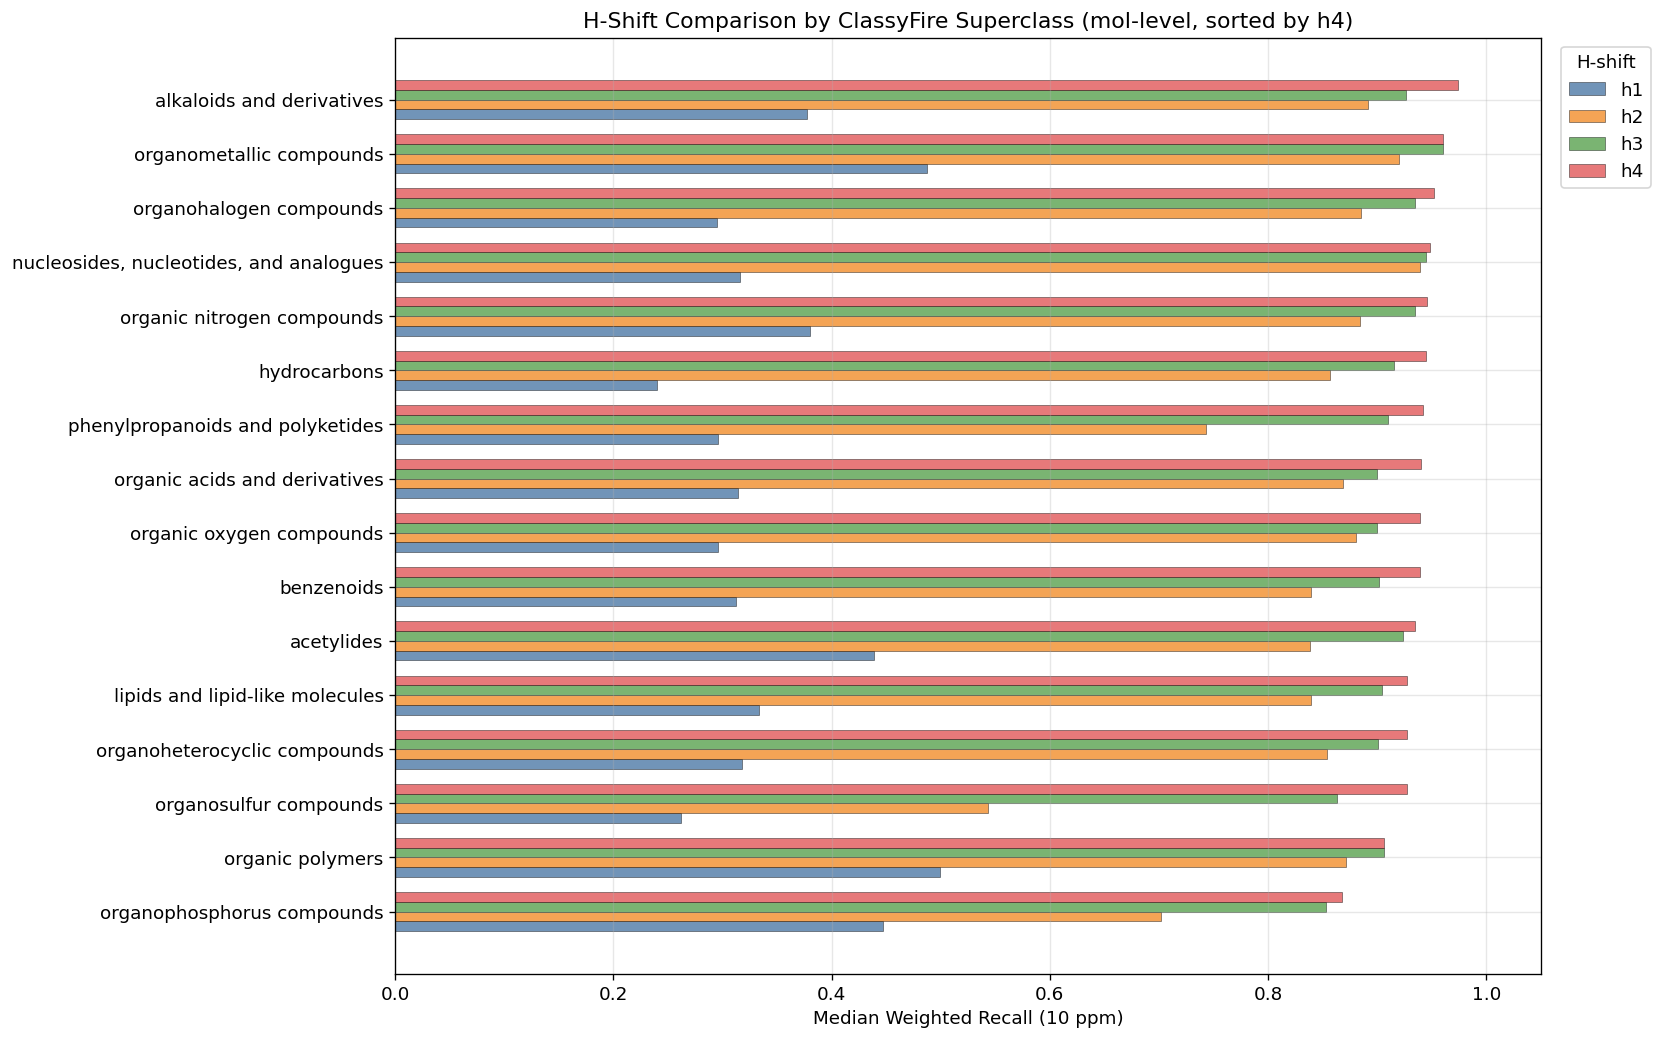

Median wrecall by superclass (sorted by h4 asc):
                                            h1     h2     h3     h4  gain_h1→h4
superklass                                                                     
organophosphorus compounds               0.447  0.702  0.853  0.868       0.421
organic polymers                         0.499  0.871  0.906  0.906       0.407
organosulfur compounds                   0.262  0.543  0.863  0.927       0.665
organoheterocyclic compounds             0.318  0.854  0.901  0.927       0.609
lipids and lipid-like molecules          0.333  0.839  0.904  0.927       0.594
acetylides                               0.439  0.838  0.924  0.935       0.496
benzenoids                               0.312  0.839  0.902  0.939       0.627
organic oxygen compounds                 0.296  0.881  0.900  0.939       0.643
organic acids and derivatives            0.314  0.869  0.900  0.940       0.626
phenylpropanoids and polyketides         0.296  0.743  0.910  0.942    

In [140]:
# ── Median wrecall by Superclass × H-shift (grouped bar) ─────────────────────
df_h = hcf.dropna(subset=["superklass"])

# Sort superclasses by h4 median descending
super_order_h = (
    df_h.groupby("superklass")["wrecall_10ppm_h4"]
    .median()
    .sort_values(ascending=True)
    .index.tolist()
)

super_medians = (
    df_h.groupby("superklass")[H_COLS]
    .median()
    .reindex(super_order_h)
    .round(3)
)

fig, ax = plt.subplots(figsize=(14, max(5, len(super_order_h) * 0.55)))
y = np.arange(len(super_order_h))
bar_height = 0.18

for i, (col, lbl, color) in enumerate(zip(H_COLS, H_LABELS, H_COLORS)):
    ax.barh(
        y + (i - 1.5) * bar_height,
        super_medians[col].values,
        height=bar_height,
        label=lbl,
        color=color,
        alpha=0.8,
        edgecolor="black",
        linewidth=0.3,
    )

ax.set_yticks(y)
ax.set_yticklabels(super_order_h)
ax.set_xlabel("Median Weighted Recall (10 ppm)")
ax.set_title("H-Shift Comparison by ClassyFire Superclass (mol-level, sorted by h4)")
ax.set_xlim(0, 1.05)
ax.legend(title="H-shift", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ── Summary table ─────────────────────────────────────────────────────────────
summary = super_medians.copy()
summary.columns = H_LABELS
summary["gain_h1→h4"] = (summary["h4"] - summary["h1"]).round(3)
print("Median wrecall by superclass (sorted by h4 asc):")
print(summary.to_string())

Fraction of molecules below wrecall threshold (mol-level):
     <0.5   <0.7   <0.9
h1  0.778  0.947  0.996
h2  0.052  0.211  0.688
h3  0.011  0.087  0.477
h4  0.010  0.058  0.363

10th-percentile (worst-case) wrecall by superclass:
                                            h1     h2     h3     h4  gain_h1→h4
superklass                                                                     
organic polymers                         0.274  0.626  0.696  0.696       0.422
phenylpropanoids and polyketides         0.213  0.468  0.609  0.697       0.484
lipids and lipid-like molecules          0.177  0.570  0.697  0.732       0.555
benzenoids                               0.207  0.582  0.721  0.744       0.537
organosulfur compounds                   0.229  0.412  0.733  0.746       0.517
organic oxygen compounds                 0.181  0.561  0.749  0.759       0.578
organoheterocyclic compounds             0.192  0.641  0.737  0.759       0.567
hydrocarbons                             0.187  

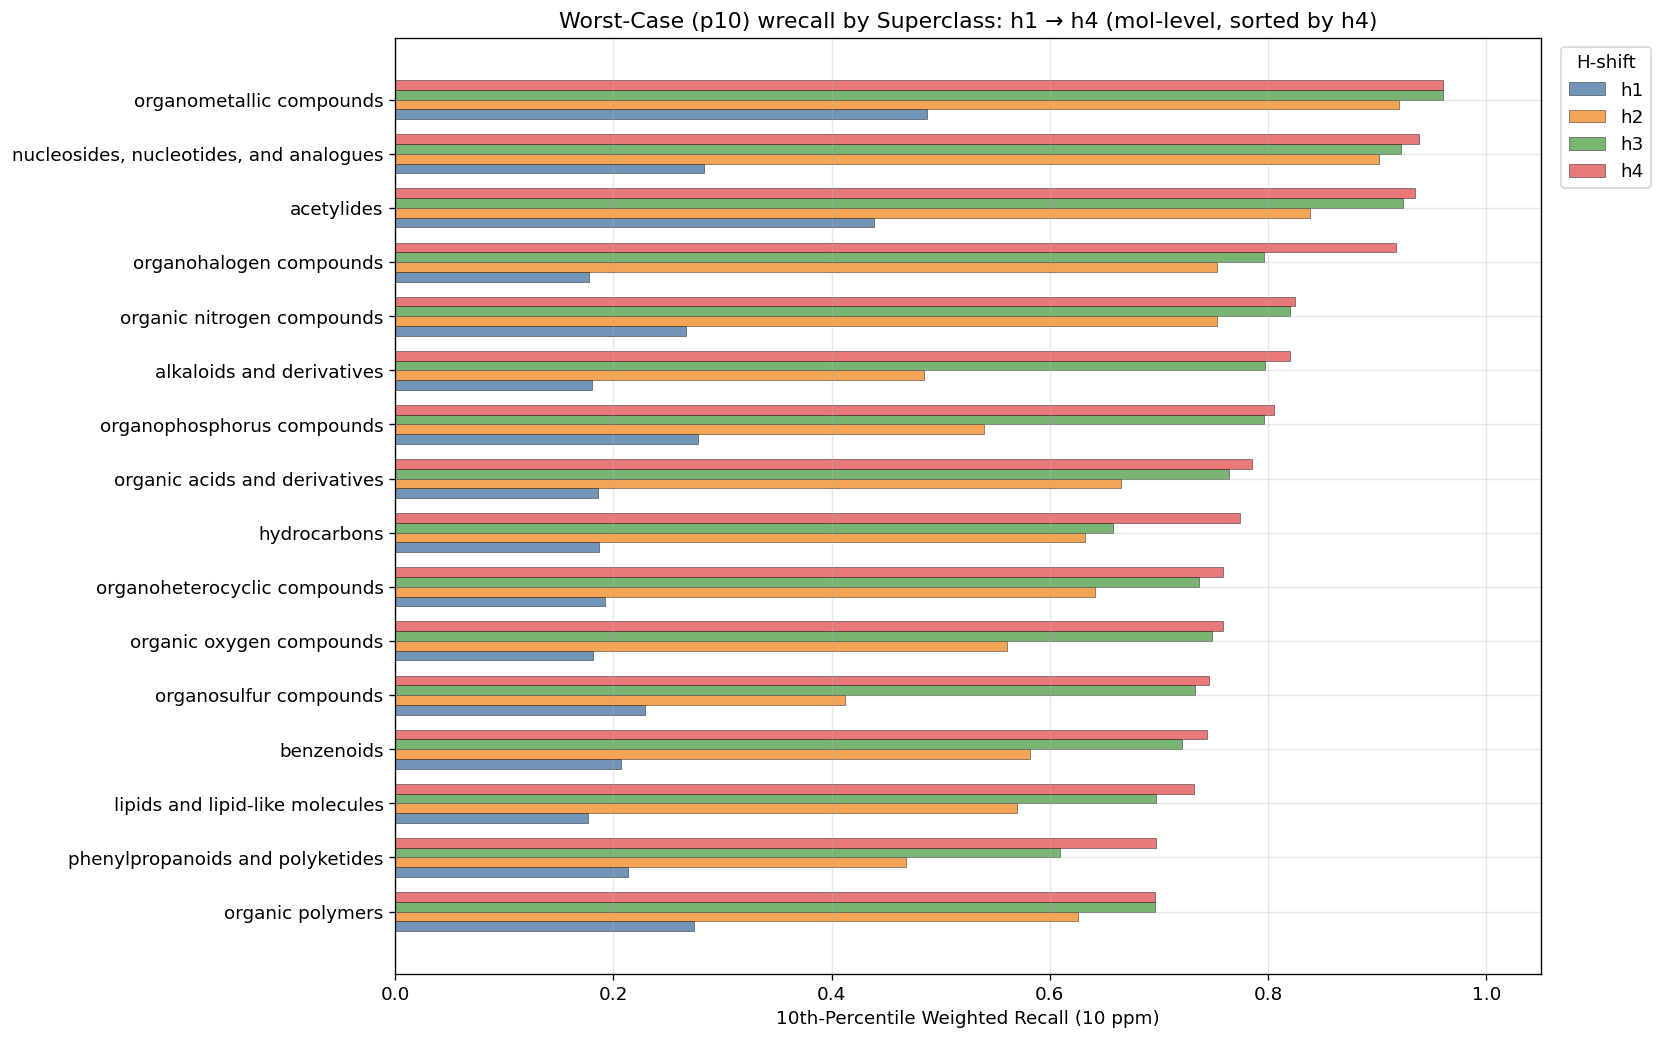


Hardest 20 molecules (lowest wrecall_10ppm_h4):
 mol_id                       superklass                               klass  wrecall_10ppm_h1  wrecall_10ppm_h2  wrecall_10ppm_h3  wrecall_10ppm_h4
    973  lipids and lipid-like molecules                       prenol lipids             0.060             0.096             0.098             0.105
    982 phenylpropanoids and polyketides                       isoflavonoids             0.128             0.180             0.213             0.223
    787    organic acids and derivatives    carboxylic acids and derivatives             0.188             0.229             0.271             0.299
     23                       benzenoids benzene and substituted derivatives             0.221             0.339             0.344             0.348
    872    organic acids and derivatives    carboxylic acids and derivatives             0.198             0.256             0.299             0.358
   1403  lipids and lipid-like molecules    steroids and 

12361

In [141]:
# ── Worst-case analysis: low-wrecall tail across h-shifts ────────────────────
# Threshold below which a molecule/spectrum is considered 'hard to explain'
THRESHOLDS = [0.5, 0.7, 0.9]

# ── Mol-level: fraction below threshold per h-shift ──────────────────────────
print("Fraction of molecules below wrecall threshold (mol-level):")
frac_df = pd.DataFrame(
    {f"<{t}": [(hcf[c] < t).mean().round(3) for c in H_COLS] for t in THRESHOLDS},
    index=H_LABELS,
)
print(frac_df.to_string())

# ── Mol-level: 10th percentile (worst-case) per superclass ───────────────────
df_h = hcf.dropna(subset=["superklass"])
super_p10 = (
    df_h.groupby("superklass")[H_COLS]
    .quantile(0.10)
    .round(3)
)
super_p10.columns = H_LABELS
super_p10["gain_h1→h4"] = (super_p10["h4"] - super_p10["h1"]).round(3)
super_p10 = super_p10.sort_values("h4", ascending=True)
print("\n10th-percentile (worst-case) wrecall by superclass:")
print(super_p10.to_string())

# ── Plot: p10 grouped bars by superclass ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, max(5, len(super_p10) * 0.55)))
y = np.arange(len(super_p10))
bar_height = 0.18
for i, (lbl, color) in enumerate(zip(H_LABELS, H_COLORS)):
    ax.barh(
        y + (i - 1.5) * bar_height,
        super_p10[lbl].values,
        height=bar_height,
        label=lbl,
        color=color,
        alpha=0.8,
        edgecolor="black",
        linewidth=0.3,
    )
ax.set_yticks(y)
ax.set_yticklabels(super_p10.index)
ax.set_xlabel("10th-Percentile Weighted Recall (10 ppm)")
ax.set_title("Worst-Case (p10) wrecall by Superclass: h1 → h4 (mol-level, sorted by h4)")
ax.set_xlim(0, 1.05)
ax.legend(title="H-shift", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ── Hardest molecules: those with lowest h4 wrecall ──────────────────────────
print("\nHardest 20 molecules (lowest wrecall_10ppm_h4):")
hard_cols = ["mol_id", "superklass", "klass"] + H_COLS
hard_cols = [c for c in hard_cols if c in hcf.columns]
print(
    hcf.nsmallest(20, "wrecall_10ppm_h4")[hard_cols]
    .round(3)
    .to_string(index=False)
)

del df_h
gc.collect()

## 4. Clean DAG Coverage: [M+H]+ Only

Sections 1–3 mix all adduct types (`[M+H]+`, `[M+Na]+`, `[M+NH4]+`, etc.).
For `[M+Na]+`/`[M+NH4]+` spectra the wrecall computation shifts every theoretical
fragment m/z by the full adduct offset (~+22 Da for Na), but those fragment ions
actually appear as `[f+H]+` in the spectrum. The ~22 Da mismatch means **no
fragment ever matches**, giving wrecall ≈ 0 regardless of DAG quality.

Filtering to `[M+H]+` isolates true DAG fragmentation gaps from this matching artifact.

In [142]:
# ── Load spec-level stats and join prec_type ─────────────────────────────
spec_stats_df = pd.read_pickle(DATA_ROOT / "frag/nps_nist23_d3/spec_stats_df.pkl")
spec_meta = pd.read_pickle(DATA_ROOT / "proc/nist23/spec_df.pkl")[
    ["spec_id", "inst_type", "nce", "ace", "prec_type"]
]
cf_df = pd.read_pickle(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl")

WRECALL_COL = "wrecall_10ppm_h4"

frag_all = (
    spec_stats_df[["spec_id", "mol_id", WRECALL_COL]]
    .merge(spec_meta, on="spec_id", how="inner")
    .merge(cf_df[["mol_id", "superklass", "klass"]], on="mol_id", how="left")
)
del spec_stats_df
gc.collect()

# ── Prec_type distribution ────────────────────────────────────────────────
print("Precursor type distribution (all spectra):")
pt_counts = frag_all["prec_type"].value_counts()
print(pt_counts.to_string())
print(f"\nTotal spectra: {len(frag_all):,}")

# ── Median wrecall by prec_type ──────────────────────────────────────────
print("\nMedian wrecall_10ppm_h4 by prec_type:")
print(
    frag_all.groupby("prec_type")[WRECALL_COL]
    .agg(["median", "mean", "count"])
    .sort_values("median", ascending=True)
    .round(3)
    .to_string()
)

Precursor type distribution (all spectra):
prec_type
[M+H]+                               7623
[M+H+2i]+                            2503
[M+H-H2O]+                           2191
[M-H]-                               1783
[M+Na]+                              1172
[2M+H]+                               954
[M+H-2H2O]+                           712
[M+NH4]+                              553
[2M-H]-                               501
[M+CHO2]-                             327
[M-H-H2O]-                            283
[2M+H+2i]+                            239
[M+2H]2+                              206
[M+H-3H2O]+                           200
[M+H-NH3]+                            191
[M-H+2i]-                             180
[M+Cl]-                               158
[M+H-CH2O2]+                          154
[M+H+4i]+                             149
[M+H-C2H4O2]+                         146
[M+H-NH3+2i]+                         119
[2M+H+3i]+                            114
[M+H-C6H10O5]+         

In [143]:
# ── Filter to [M+H]+ FT spectra ──────────────────────────────────────────────
frag_mh = frag_all[
    (frag_all["prec_type"] == "[M+H]+") & (frag_all["inst_type"] == "FT")
].copy()
print(f"[M+H]+ FT spectra: {len(frag_mh):,}  |  "
      f"CF coverage: {frag_mh['superklass'].notna().mean():.1%}")
print(f"Overall median wrecall: {frag_mh[WRECALL_COL].median():.3f}")

# ── CE-adjusted wrecall ([M+H]+ FT only) ─────────────────────────────────────
frag_mh["ce_bin"] = frag_mh.groupby("inst_type", observed=True)["nce"].transform(
    lambda x: pd.qcut(x.rank(method="first"), q=3, labels=["low", "mid", "high"])
)
bin_med = frag_mh.groupby(["inst_type", "ce_bin"], observed=True)[WRECALL_COL].transform("median")
frag_mh["wrecall_adj"] = frag_mh[WRECALL_COL] - bin_med

# ── CE-adjusted by superclass ([M+H]+ FT) ────────────────────────────────────
df_mh = frag_mh.dropna(subset=["superklass"])
super_mh = (
    df_mh.groupby("superklass")[[WRECALL_COL, "wrecall_adj"]]
    .agg("median")
    .rename(columns={WRECALL_COL: "med_raw", "wrecall_adj": "med_adj"})
    .join(df_mh.groupby("superklass")[WRECALL_COL].count().rename("n_specs"))
    .sort_values("med_adj")
    .round(3)
)
print("\nSuperclass — [M+H]+ FT only (sorted by CE-adj, low = true DAG gap):")
print(super_mh.to_string())

[M+H]+ FT spectra: 6,597  |  CF coverage: 100.0%
Overall median wrecall: 0.982

Superclass — [M+H]+ FT only (sorted by CE-adj, low = true DAG gap):
                                         med_raw  med_adj  n_specs
superklass                                                        
organosulfur compounds                     0.955   -0.022       29
organic oxygen compounds                   0.965   -0.014      206
organoheterocyclic compounds               0.977   -0.006     2148
lipids and lipid-like molecules            0.978   -0.004     3050
organic acids and derivatives              0.993    0.010      389
organic nitrogen compounds                 0.996    0.010       93
benzenoids                                 0.996    0.012      316
phenylpropanoids and polyketides           0.995    0.012      230
acetylides                                 0.989    0.013        4
alkaloids and derivatives                  0.998    0.013       79
organohalogen compounds                    0.997

Classes with ≥10 [M+H]+ FT spectra: 64

All classes sorted by median wrecall (lowest = most problematic):
                                          med   mean  n_specs    p10  frac_below_0.9
klass                                                                               
isoquinolines and derivatives           0.823  0.748       46  0.398           0.587
phenol esters                           0.849  0.728       15  0.325           0.533
benzofurans                             0.858  0.782      228  0.473           0.601
saccharolipids                          0.874  0.706       46  0.217           0.522
benzothiazoles                          0.878  0.760       18  0.461           0.500
naphthopyrans                           0.911  0.765       50  0.429           0.480
diazinanes                              0.917  0.826      132  0.498           0.470
benzazepines                            0.920  0.790       14  0.464           0.429
pyrazolopyridines                       0.92

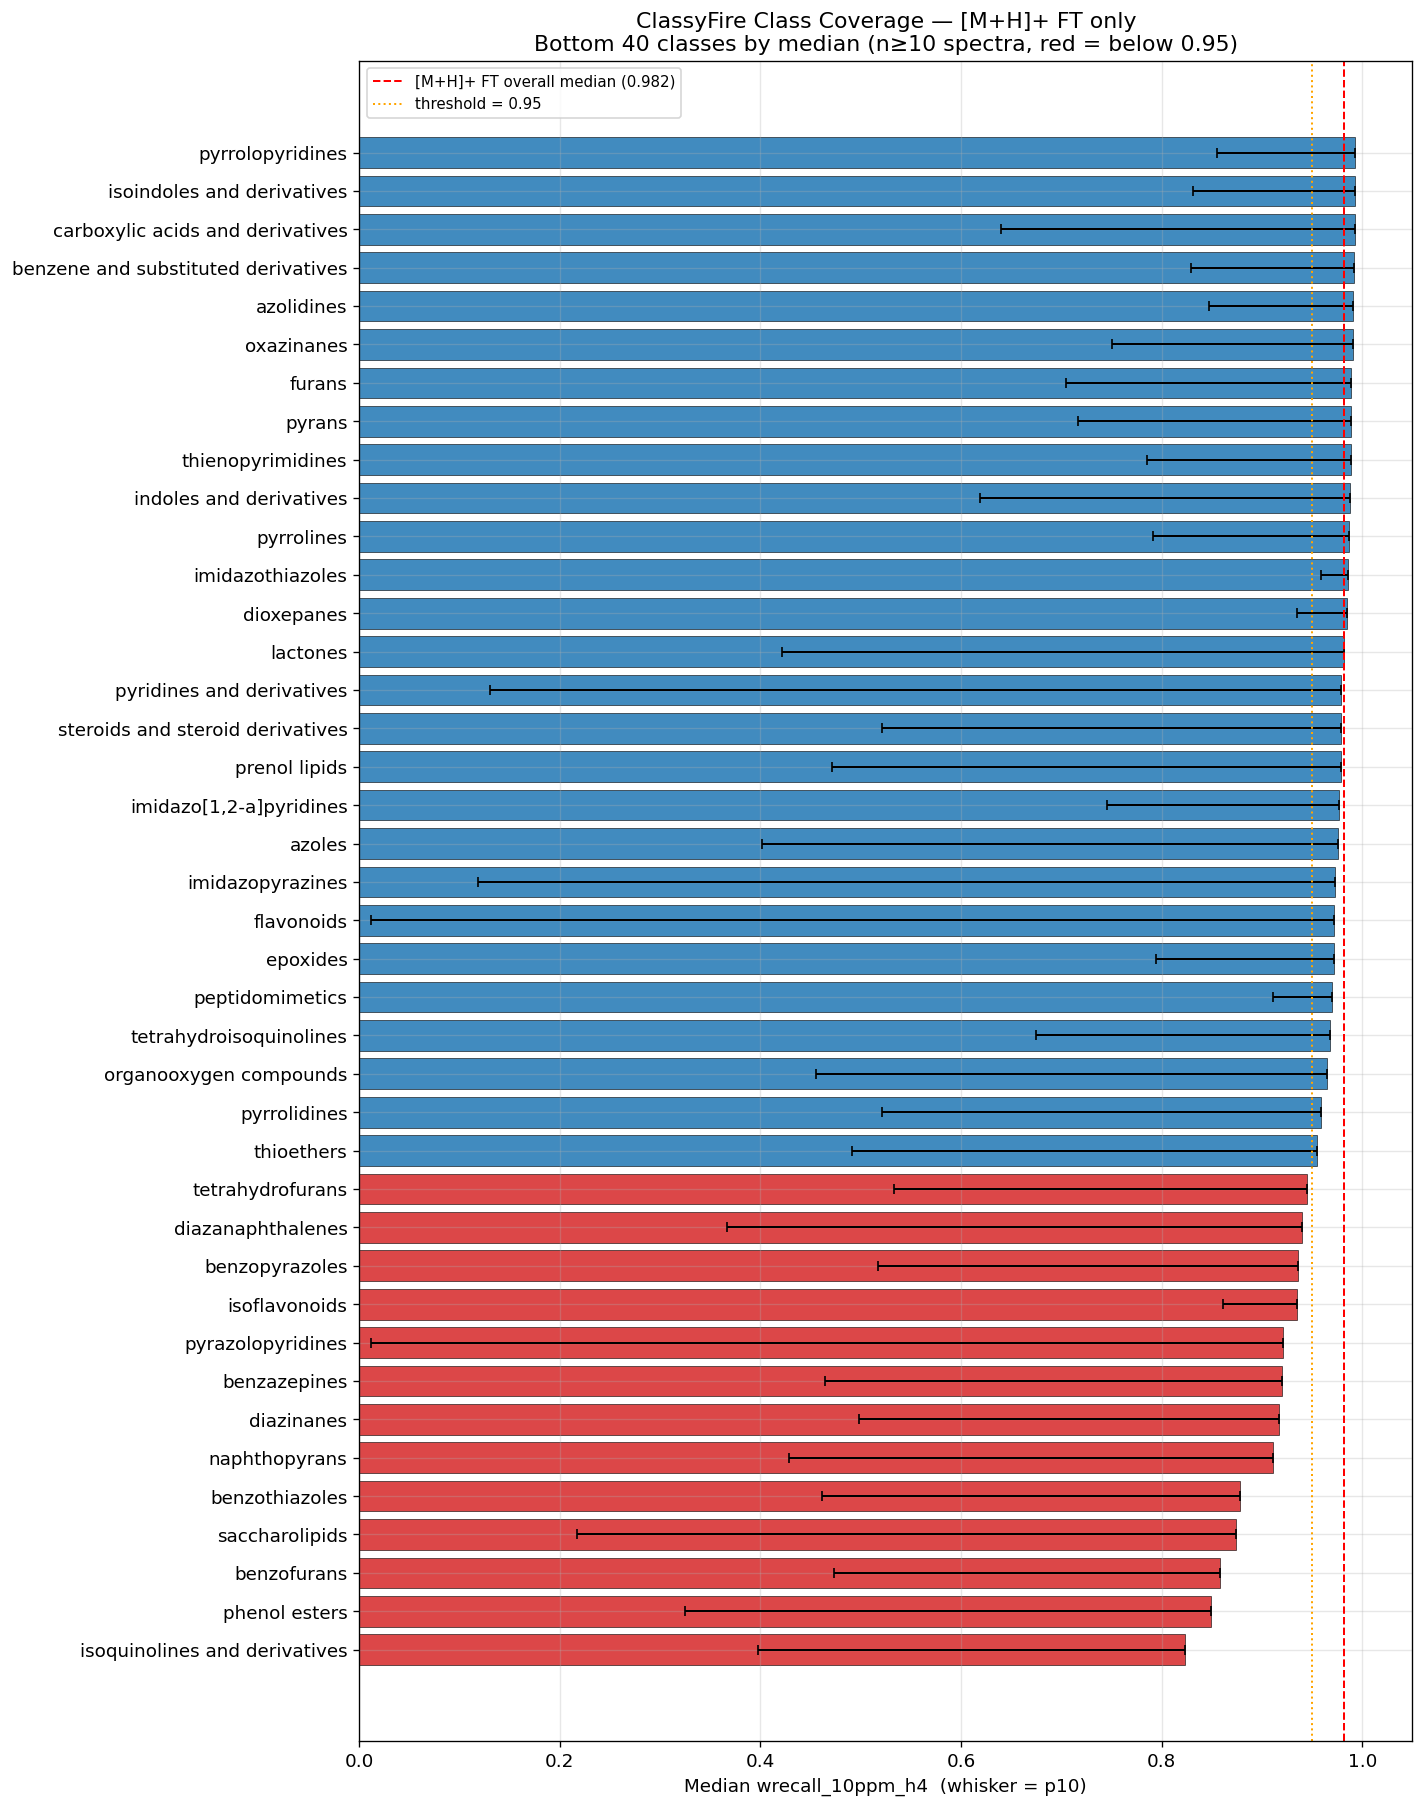

In [144]:
# ── Class-level coverage ([M+H]+ FT) ─────────────────────────────────────────
# Use all classes with ≥ 10 spectra for stable estimates
klass_counts = df_mh["klass"].value_counts()
klass_keep = klass_counts[klass_counts >= 10].index
df_mh_k = df_mh[df_mh["klass"].isin(klass_keep)].dropna(subset=["klass"])

klass_stats_mh = (
    df_mh_k.groupby("klass")[WRECALL_COL]
    .agg(["median", "mean", "count",
          lambda x: x.quantile(0.10)])
    .rename(columns={"median": "med", "mean": "mean",
                     "count": "n_specs", "<lambda_0>": "p10"})
    .sort_values("med", ascending=True)
    .round(3)
)
klass_stats_mh["frac_below_0.9"] = (
    df_mh_k.groupby("klass")[WRECALL_COL]
    .apply(lambda x: (x < 0.9).mean())
    .round(3)
)

print(f"Classes with ≥10 [M+H]+ FT spectra: {len(klass_stats_mh)}")
print("\nAll classes sorted by median wrecall (lowest = most problematic):")
print(klass_stats_mh.to_string())

# ── Plot: bottom 30 classes by median wrecall ────────────────────────────────
LOW_THR = 0.95  # classes below this are highlighted
low_klass = klass_stats_mh[klass_stats_mh["med"] < LOW_THR]
print(f"\nClasses with median wrecall < {LOW_THR} ([M+H]+ FT): {len(low_klass)}")
print(low_klass.to_string())

plot_df = klass_stats_mh.head(min(40, len(klass_stats_mh)))
overall_mh_med = df_mh[WRECALL_COL].median()

fig, ax = plt.subplots(figsize=(12, max(6, len(plot_df) * 0.38)))
colors = ["#d62728" if v < LOW_THR else "#1f77b4" for v in plot_df["med"]]
bars = ax.barh(plot_df.index, plot_df["med"],
               color=colors, edgecolor="black", linewidth=0.4, alpha=0.85)
ax.errorbar(
    plot_df["med"], np.arange(len(plot_df)),
    xerr=[plot_df["med"] - plot_df["p10"],
          np.zeros(len(plot_df))],  # only show downward whisker (p10)
    fmt="none", color="black", linewidth=1.2, capsize=3,
)
ax.axvline(overall_mh_med, color="red", linestyle="--",
           linewidth=1.2, label=f"[M+H]+ FT overall median ({overall_mh_med:.3f})")
ax.axvline(LOW_THR, color="orange", linestyle=":",
           linewidth=1.2, label=f"threshold = {LOW_THR}")
ax.set_xlabel(f"Median {WRECALL_COL}  (whisker = p10)")
ax.set_title(
    f"ClassyFire Class Coverage — [M+H]+ FT only\n"
    f"Bottom {len(plot_df)} classes by median (n≥10 spectra, red = below {LOW_THR})"
)
ax.set_xlim(0, 1.05)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

Adduct artifact per superclass (MH_only − all_adducts):
Positive = class wrecall was dragged down by non-[M+H]+ spectra
                                         all_adducts  MH_only  adduct_artifact
superklass                                                                    
acetylides                                     0.966    0.989            0.022
nucleosides, nucleotides, and analogues        0.990    1.000            0.010
benzenoids                                     0.988    0.996            0.008
phenylpropanoids and polyketides               0.988    0.995            0.007
organic nitrogen compounds                     0.990    0.996            0.006
alkaloids and derivatives                      0.994    0.998            0.004
organic acids and derivatives                  0.991    0.993            0.002
organosulfur compounds                         0.954    0.955            0.001
organohalogen compounds                        0.997    0.997            0.000
lipids and 

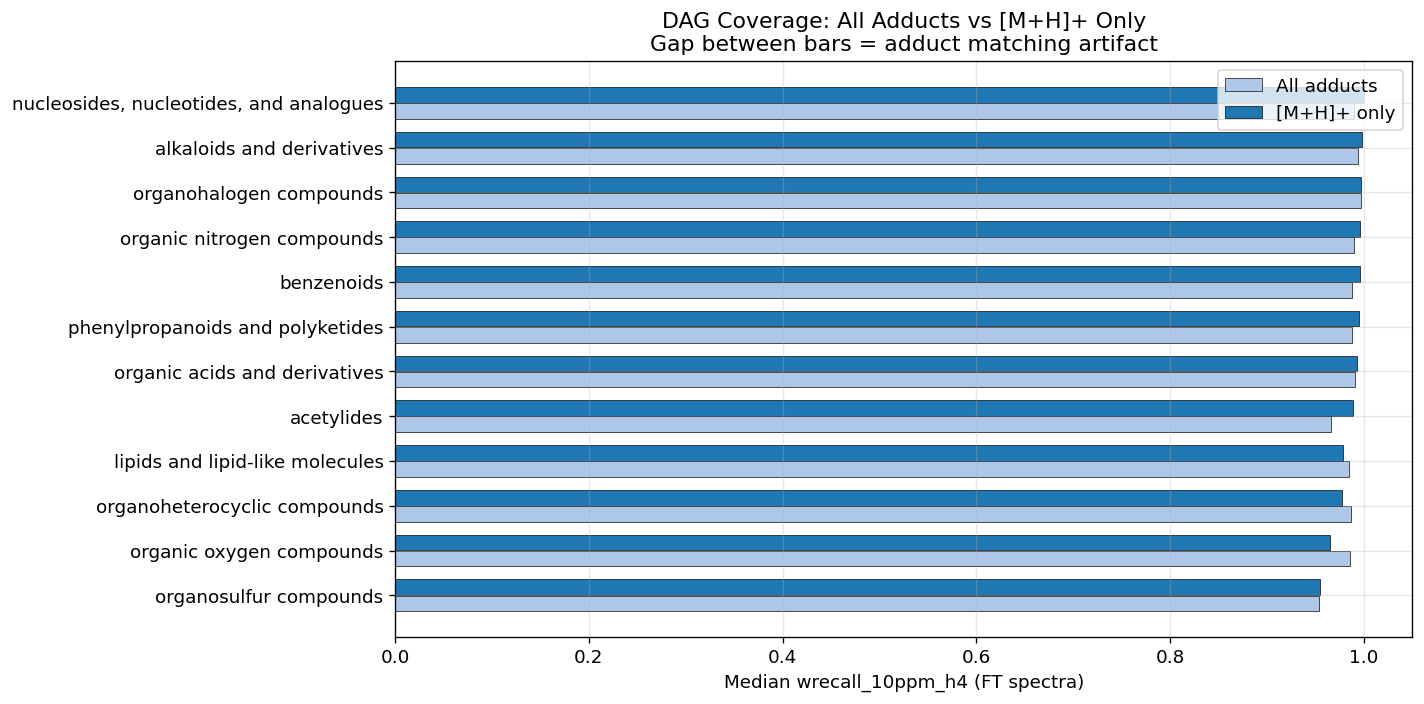

In [145]:
# ── Side-by-side: all adducts vs [M+H]+ only, by superclass ─────────────────
frag_all_ft = frag_all[frag_all["inst_type"] == "FT"].dropna(subset=["superklass"])

all_med = frag_all_ft.groupby("superklass")[WRECALL_COL].median().rename("all_adducts")
mh_med  = df_mh.groupby("superklass")[WRECALL_COL].median().rename("MH_only")
compare = pd.concat([all_med, mh_med], axis=1).dropna()
compare["adduct_artifact"] = (compare["MH_only"] - compare["all_adducts"]).round(3)
compare = compare.sort_values("adduct_artifact", ascending=False).round(3)

print("Adduct artifact per superclass (MH_only − all_adducts):")
print("Positive = class wrecall was dragged down by non-[M+H]+ spectra")
print(compare.to_string())

# ── Plot ──────────────────────────────────────────────────────────────────────
super_order_c = compare.sort_values("MH_only", ascending=True).index.tolist()
y = np.arange(len(super_order_c))

fig, ax = plt.subplots(figsize=(12, max(5, len(super_order_c) * 0.5)))
ax.barh(y - 0.18, compare.reindex(super_order_c)["all_adducts"],
        height=0.35, label="All adducts", color="#aec7e8", edgecolor="black", linewidth=0.4)
ax.barh(y + 0.18, compare.reindex(super_order_c)["MH_only"],
        height=0.35, label="[M+H]+ only", color="#1f77b4", edgecolor="black", linewidth=0.4)
ax.set_yticks(y)
ax.set_yticklabels(super_order_c)
ax.set_xlabel(f"Median {WRECALL_COL} (FT spectra)")
ax.set_title("DAG Coverage: All Adducts vs [M+H]+ Only\n"
             "Gap between bars = adduct matching artifact")
ax.set_xlim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

del frag_all_ft

In [146]:
# ── Worst-case ([M+H]+ FT): p10 by superclass ────────────────────────────────
super_p10_mh = (
    df_mh.groupby("superklass")[WRECALL_COL]
    .quantile(0.10)
    .sort_values()
    .round(3)
)
print("10th-percentile wrecall_10ppm_h4 by superclass ([M+H]+ FT only):")
print("Classes below 0.9 have genuine fragmentation DAG gaps")
print(super_p10_mh.to_string())

# ── Fraction of [M+H]+ FT spectra below threshold ────────────────────────────
THRESHOLDS = [0.5, 0.7, 0.9]
print("\nFraction of [M+H]+ FT spectra below wrecall threshold by superclass:")
frac_rows = []
for s in super_p10_mh.index:
    vals = df_mh[df_mh["superklass"] == s][WRECALL_COL]
    row = {"superklass": s}
    for t in THRESHOLDS:
        row[f"frac_below_{t}"] = round((vals < t).mean(), 3)
    frac_rows.append(row)
frac_mh = pd.DataFrame(frac_rows).set_index("superklass").reindex(super_p10_mh.index)
print(frac_mh.to_string())

del frag_all, frag_mh, df_mh
gc.collect()

10th-percentile wrecall_10ppm_h4 by superclass ([M+H]+ FT only):
Classes below 0.9 have genuine fragmentation DAG gaps
superklass
organic oxygen compounds                   0.455
lipids and lipid-like molecules            0.478
organosulfur compounds                     0.491
organoheterocyclic compounds               0.537
alkaloids and derivatives                  0.651
phenylpropanoids and polyketides           0.673
organic nitrogen compounds                 0.702
organic acids and derivatives              0.718
benzenoids                                 0.784
organohalogen compounds                    0.847
acetylides                                 0.917
nucleosides, nucleotides, and analogues    1.000

Fraction of [M+H]+ FT spectra below wrecall threshold by superclass:
                                         frac_below_0.5  frac_below_0.7  frac_below_0.9
superklass                                                                             
organic oxygen compounds            

7760